In [1]:
import pandas as pd
import re
import numpy as np
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.feature_extraction.text import TfidfVectorizer

In [2]:
df = pd.read_csv('IMDB Dataset.csv')
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [3]:
df.shape

(50000, 2)

In [4]:
def clean_text(text):
    text = text.lower()                       
    text = re.sub(r'<.*?>', ' ', text)         
    text = re.sub(r'[^a-z\s]', ' ', text)      
    words = text.split()                      
    words = [w for w in words if w not in ENGLISH_STOP_WORDS]
    return ' '.join(words)

In [5]:
df['clean_text'] = df['review'].apply(clean_text)
df[['review', 'clean_text']].head()

,review,clean_text
0,One of the other reviewers has mentioned that ...,reviewers mentioned watching just oz episode l...
1,A wonderful little production. <br /><br />The...,wonderful little production filming technique ...
2,I thought this was a wonderful way to spend ti...,thought wonderful way spend time hot summer we...
3,Basically there's a family where a little boy ...,basically s family little boy jake thinks s zo...
4,"Petter Mattei's ""Love in the Time of Money"" is...",petter mattei s love time money visually stunn...


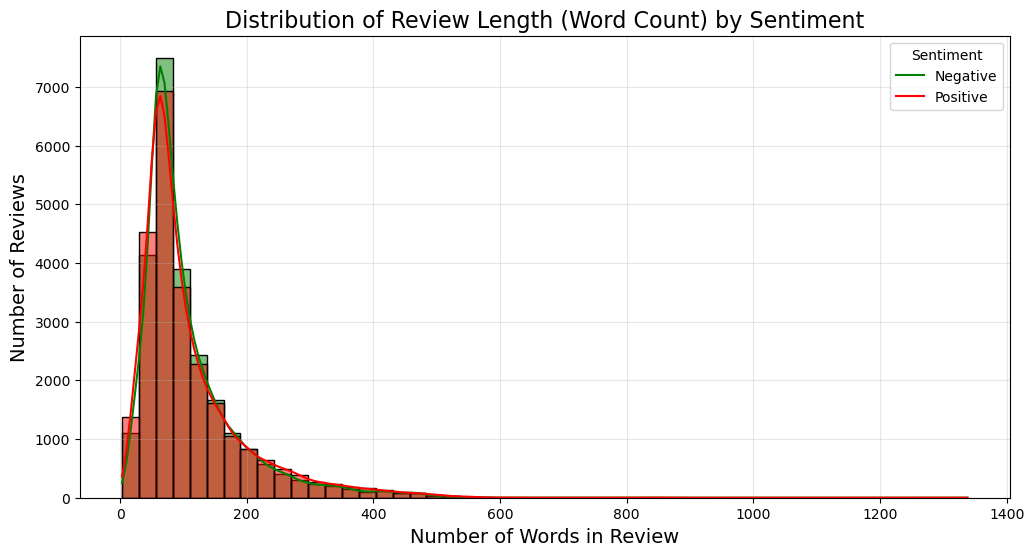

Average word count in positive reviews: 111.89
Average word count in negative reviews: 109.18
Shortest review: 3 words
Longest review: 1338 words


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

df['word_count'] = df['clean_text'].apply(lambda x: len(x.split()))

plt.figure(figsize=(12, 6))
sns.histplot(data=df, x='word_count', hue='sentiment', bins=50, kde=True, palette=['red', 'green'])
plt.title('Distribution of Review Length (Word Count) by Sentiment', fontsize=16)
plt.xlabel('Number of Words in Review', fontsize=14)
plt.ylabel('Number of Reviews', fontsize=14)
plt.legend(title='Sentiment', labels=['Negative', 'Positive'])
plt.grid(True, alpha=0.3)
plt.show()

print("Average word count in positive reviews:", round(df[df['sentiment'] == 'positive']['word_count'].mean(), 2))
print("Average word count in negative reviews:", round(df[df['sentiment'] == 'negative']['word_count'].mean(), 2))
print("Shortest review:", df['word_count'].min(), "words")
print("Longest review:", df['word_count'].max(), "words")

C:\Users\Omar Ahmed\AppData\Local\Temp\ipykernel_29584\1625228426.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=pos_df, y='Word', x='Frequency', ax=axes[0], palette='Greens_d')
C:\Users\Omar Ahmed\AppData\Local\Temp\ipykernel_29584\1625228426.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=neg_df, y='Word', x='Frequency', ax=axes[1], palette='Reds_d')


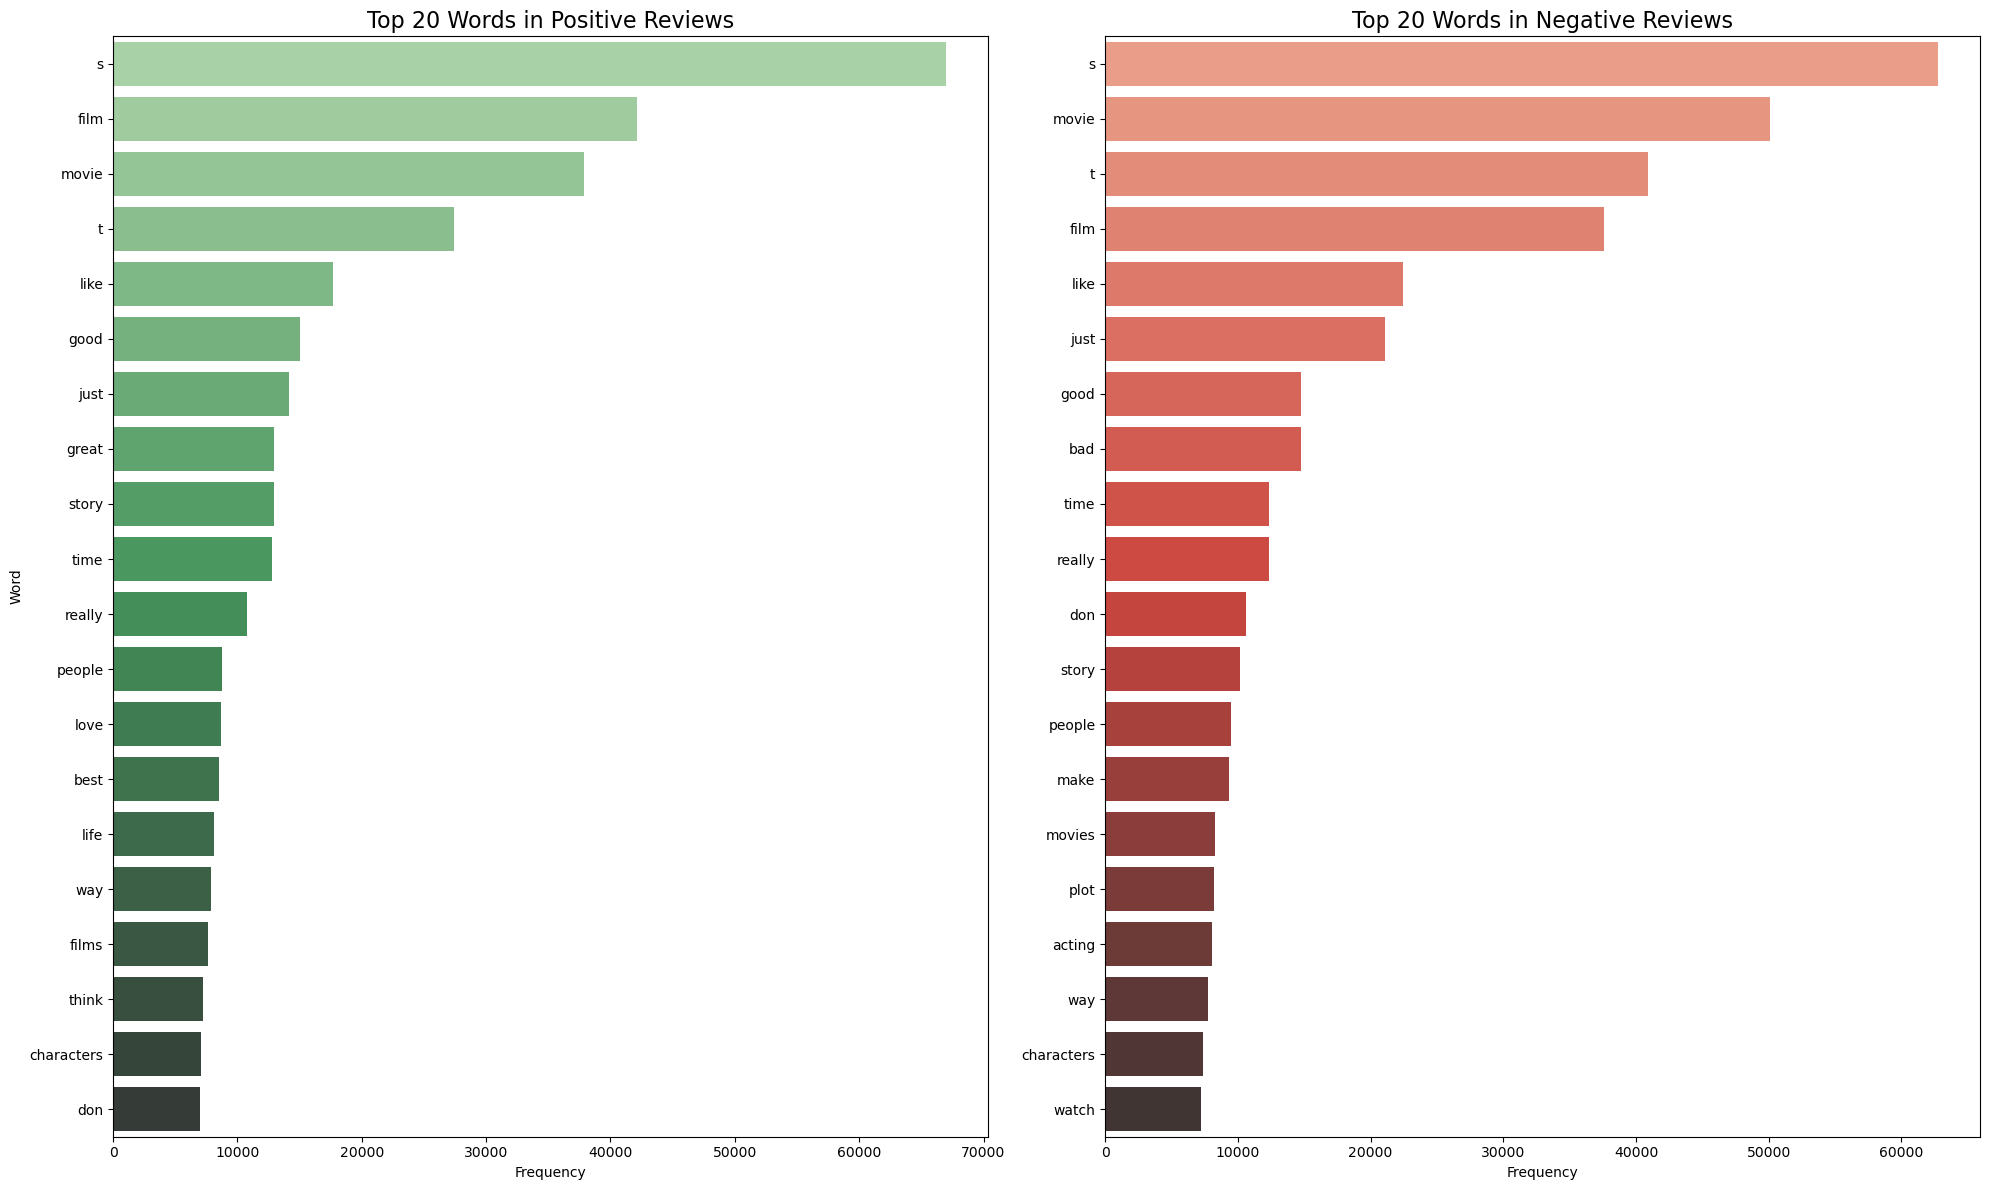

In [29]:
from collections import Counter

positive_words = ' '.join(df[df['sentiment'] == 'positive']['clean_text']).split()
negative_words = ' '.join(df[df['sentiment'] == 'negative']['clean_text']).split()

top_positive = Counter(positive_words).most_common(20)
top_negative = Counter(negative_words).most_common(20)

pos_df = pd.DataFrame(top_positive, columns=['Word', 'Frequency'])
neg_df = pd.DataFrame(top_negative, columns=['Word', 'Frequency'])

fig, axes = plt.subplots(1, 2, figsize=(20, 12))

sns.barplot(data=pos_df, y='Word', x='Frequency', ax=axes[0], palette='Greens_d')
axes[0].set_title('Top 20 Words in Positive Reviews', fontsize=16)
axes[0].set_xlabel('Frequency')
axes[0].set_ylabel('Word')

sns.barplot(data=neg_df, y='Word', x='Frequency', ax=axes[1], palette='Reds_d')
axes[1].set_title('Top 20 Words in Negative Reviews', fontsize=16)
axes[1].set_xlabel('Frequency')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

In [8]:
%pip install wordcloud

Note: you may need to restart the kernel to use updated packages.


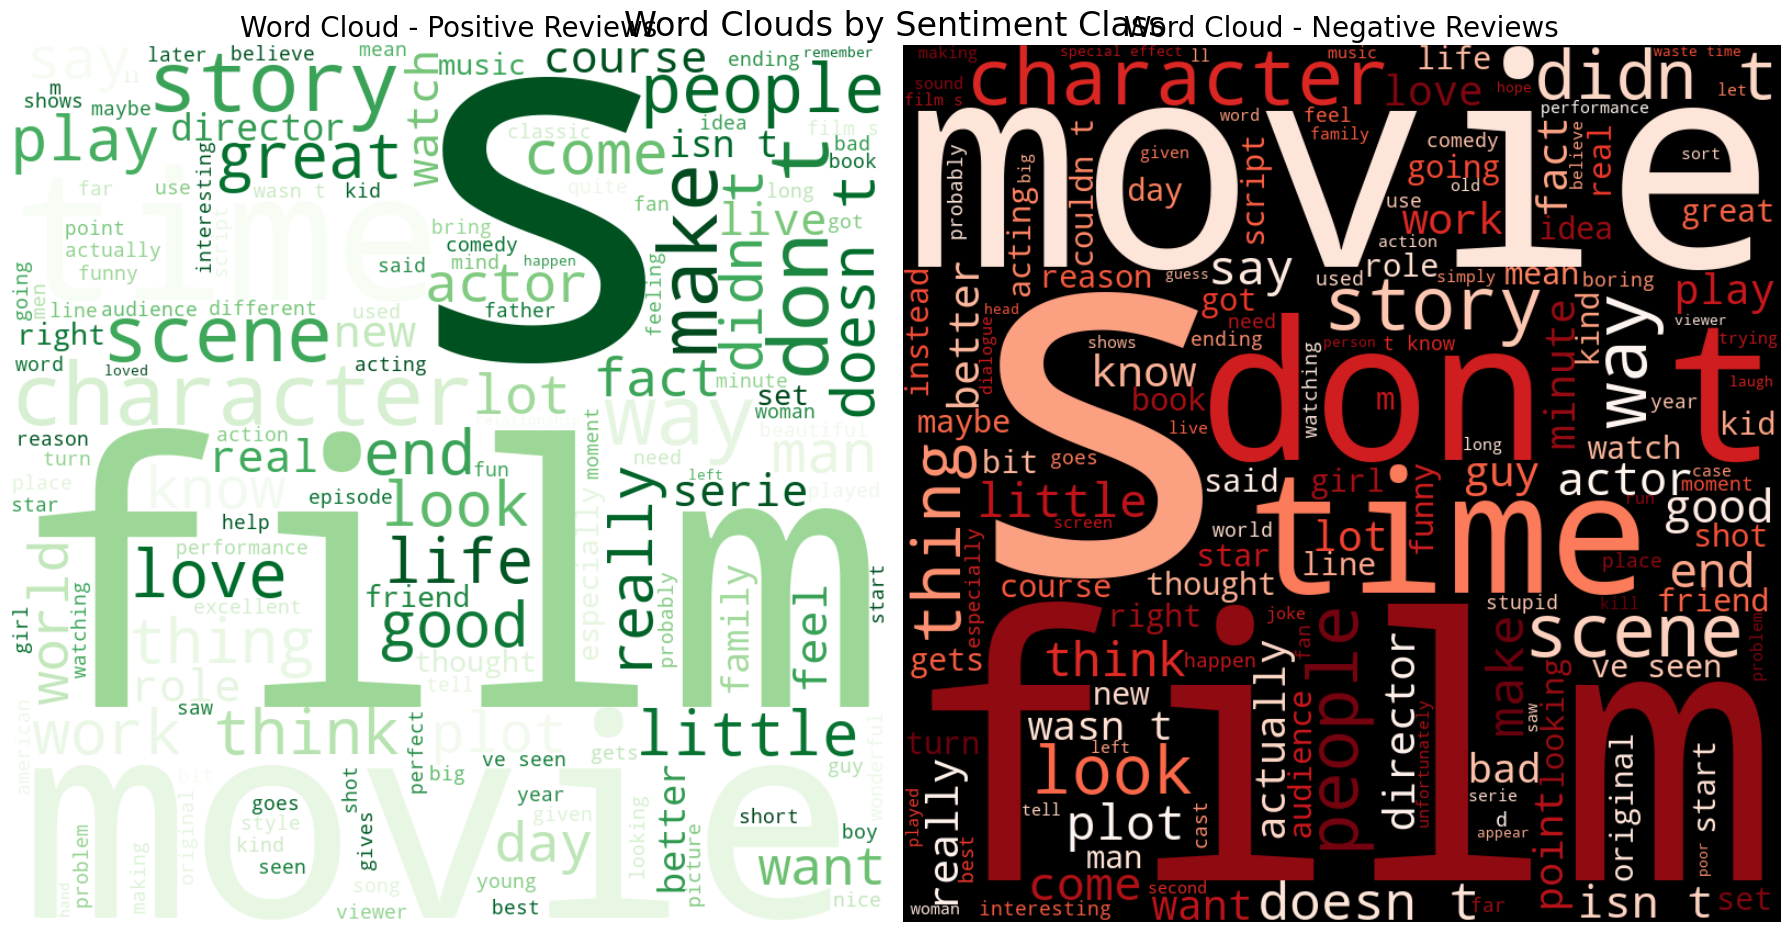

In [9]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

positive_text = ' '.join(df[df['sentiment'] == 'positive']['clean_text'])
negative_text = ' '.join(df[df['sentiment'] == 'negative']['clean_text'])

fig, axes = plt.subplots(1, 2, figsize=(18, 10))

wordcloud_pos = WordCloud(
    width=800, 
    height=800, 
    background_color='white', 
    colormap='Greens', 
    max_words=150, 
    contour_width=1, 
    contour_color='green'
).generate(positive_text)

axes[0].imshow(wordcloud_pos, interpolation='bilinear')
axes[0].set_title('Word Cloud - Positive Reviews', fontsize=20)
axes[0].axis('off')

wordcloud_neg = WordCloud(
    width=800, 
    height=800, 
    background_color='black', 
    colormap='Reds', 
    max_words=150, 
    contour_width=1, 
    contour_color='darkred'
).generate(negative_text)

axes[1].imshow(wordcloud_neg, interpolation='bilinear')
axes[1].set_title('Word Cloud - Negative Reviews', fontsize=20)
axes[1].axis('off')

plt.suptitle('Word Clouds by Sentiment Class', fontsize=24, y=0.95)
plt.tight_layout()
plt.show()

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.feature_selection import SelectKBest, chi2

In [11]:
X_text = df["clean_text"].astype(str)
y = df["sentiment"].astype(str)

In [12]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text, y, test_size=0.2, random_state=42, stratify=y
)

In [13]:
vectorizer = CountVectorizer(
    stop_words="english",
    max_df=0.2,
    min_df=2,          # optional: ignore very rare words
    )

In [14]:
X_train = vectorizer.fit_transform(X_train_text)
X_test  = vectorizer.transform(X_test_text)

In [15]:
k = 10000  # try 5000 / 10000 / 20000 / 'all'
selector = SelectKBest(score_func=chi2, k=k)
X_train_sel = selector.fit_transform(X_train, y_train)
X_test_sel  = selector.transform(X_test)

In [16]:
from MultinomialNB import SimpleCountMultinomialNB

In [17]:
model = SimpleCountMultinomialNB(alpha=1)
model.fit(X_train_sel, y_train)

In [18]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [19]:
Y_predict = model.predict(X_test_sel )
accuracy  = accuracy_score(y_test, Y_predict)
precision = precision_score(y_test, Y_predict, pos_label='positive')
recall    = recall_score(y_test, Y_predict, pos_label='positive')
f1        = f1_score(y_test, Y_predict, pos_label='positive')

In [20]:
print("Model Performance Metrics:")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

Model Performance Metrics:
Accuracy : 0.8591
Precision: 0.8718
Recall   : 0.8420
F1-score : 0.8566


In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

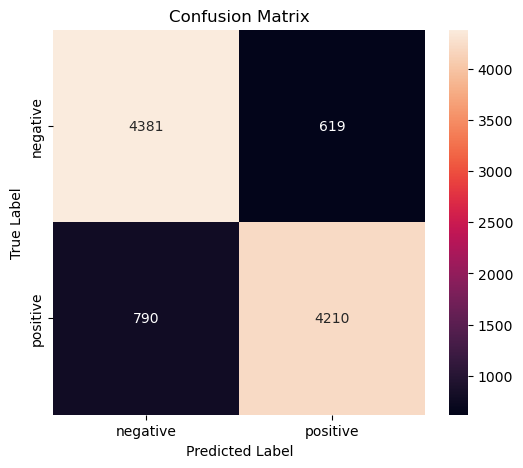

In [22]:
cm = confusion_matrix(y_test, Y_predict, labels=model.classes_)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='rocket',
            xticklabels=model.classes_,
            yticklabels=model.classes_)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

In [23]:
from sklearn.metrics import classification_report

In [24]:
print(f" Detailed Classification Report{classification_report(y_test, Y_predict)}")

 Detailed Classification Report              precision    recall  f1-score   support

    negative       0.85      0.88      0.86      5000
    positive       0.87      0.84      0.86      5000

    accuracy                           0.86     10000
   macro avg       0.86      0.86      0.86     10000
weighted avg       0.86      0.86      0.86     10000



In [25]:
def test_single_review(review_text):
    cleaned = clean_text(review_text)
    vect = vectorizer.transform([cleaned])
    vect_sel = selector.transform(vect)
    return model.predict(vect_sel)[0]

In [26]:
review = "This movie was boring and a waste of time."
print("Prediction:", test_single_review(review))

Prediction: negative


In [27]:
review = """I had really high expectations for this movie because of the cast and the trailers, 
but honestly, it was a rollercoaster of emotions. The first half was absolutely fantastic—stunning visuals,
great character development, and the dialogue felt natural and engaging. I found myself completely immersed in the story.
However, the second half dragged a bit, and some plot points felt rushed and inconsistent. 
A few characters' actions didn't make much sense, which was frustrating because the buildup made them seem more significant. 
Still, the soundtrack was amazing, and the cinematography was breathtaking, which partially redeemed the pacing issues. 
Overall, it’s a movie I would recommend for its creativity and emotional moments, but I wish the ending had been stronger and more satisfying."""
print("Prediction:", test_single_review(review))

Prediction: positive


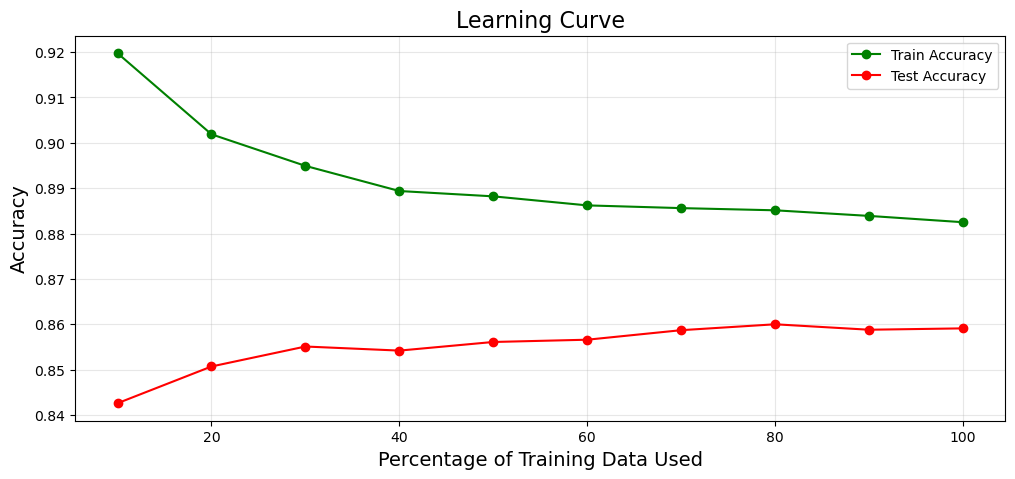

In [28]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.utils import shuffle
from sklearn.metrics import accuracy_score

# Shuffle training data
X_train_sel, y_train = shuffle(X_train_sel, y_train, random_state=42)

# Learning curve
fractions = np.linspace(0.1, 1.0, 10)
train_acc = []
test_acc = []
n_train_samples = X_train_sel.shape[0]
repeats = 3

for frac in fractions:
    acc_train_list = []
    acc_test_list = []
    n_samples = int(n_train_samples * frac)
    for _ in range(repeats):
        X_sub = X_train_sel[:n_samples]
        y_sub = y_train.iloc[:n_samples]
        model = SimpleCountMultinomialNB(alpha=1)
        model.fit(X_sub, y_sub)
        acc_train_list.append(accuracy_score(y_sub, model.predict(X_sub)))
        acc_test_list.append(accuracy_score(y_test, model.predict(X_test_sel)))
    train_acc.append(np.mean(acc_train_list))
    test_acc.append(np.mean(acc_test_list))

# Plot learning curve
plt.figure(figsize=(12,5))
plt.plot(fractions*100, train_acc, marker='o', label='Train Accuracy', color='green')
plt.plot(fractions*100, test_acc, marker='o', label='Test Accuracy', color='red')
plt.title('Learning Curve', fontsize=16)
plt.xlabel('Percentage of Training Data Used', fontsize=14)
plt.ylabel('Accuracy', fontsize=14)
plt.grid(alpha=0.3)
plt.legend()
plt.show()
